# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Pranaja Adyatma Budiman | 5054251009 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **TensorFlow / Keras** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan tf.keras.utils.set_random_seed(42).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks

# Seed untuk reproduksibilitas (mengatur seed Python, NumPy, dan TensorFlow sekaligus)
tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: []


In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv( "Churn_Modelling.csv")

# Beberapa baris pertama
display(df.head())

# Jumlah baris dan kolom
print("Jumlah baris, kolom:", df.shape)

# Tipe data dan info dasar
df.info()

# Statistik deskriptif (numerik dan kategorikal)
display(df.describe())
display(df.describe(include="object"))

# Missing value per kolom
print("Missing value per kolom:")
print(df.isnull().sum())

# Proporsi kelas target, penting untuk bagian class weight nanti
print("\nDistribusi target (Exited):")
print(df["Exited"].value_counts())
print(df["Exited"].value_counts(normalize=True).round(3))

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Jumlah baris, kolom: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


C:\Users\pranaja\AppData\Local\Temp\ipykernel_26820\4163296169.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,Surname,Geography,Gender
count,10000,10000,10000
unique,2932,3,2
top,Smith,France,Male
freq,32,5014,5457


Missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Distribusi target (Exited):
Exited
0    7963
1    2037
Name: count, dtype: int64
Exited
0    0.796
1    0.204
Name: proportion, dtype: float64


C:\Users\pranaja\AppData\Local\Temp\ipykernel_26820\959780768.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette=["#4C72B0", "#C44E52"], ax=ax)
C:\Users\pranaja\AppData\Local\Temp\ipykernel_26820\959780768.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Tidak churn (0)", "Churn (1)"])


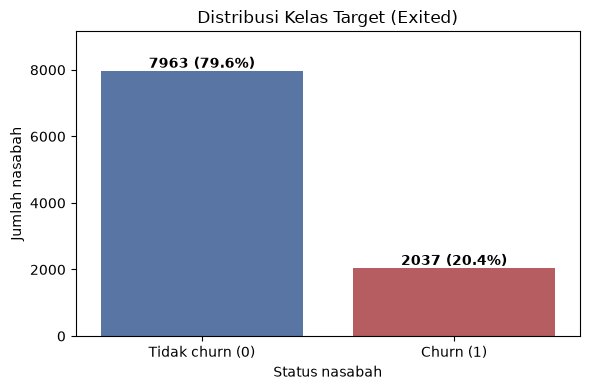

Rasio kelas 0 : kelas 1 = 3.91 : 1


In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
counts = df["Exited"].value_counts().sort_index()
percent = df["Exited"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, palette=["#4C72B0", "#C44E52"], ax=ax)

# Label jumlah dan persentase di atas tiap bar
for i, (c, p) in enumerate(zip(counts.values, percent.values)):
    ax.text(i, c + 100, f"{c} ({p:.1f}%)", ha="center", fontweight="bold")

ax.set_xticklabels(["Tidak churn (0)", "Churn (1)"])
ax.set_xlabel("Status nasabah")
ax.set_ylabel("Jumlah nasabah")
ax.set_title("Distribusi Kelas Target (Exited)")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

# Rasio ketidakseimbangan
print(f"Rasio kelas 0 : kelas 1 = {counts[0] / counts[1]:.2f} : 1")

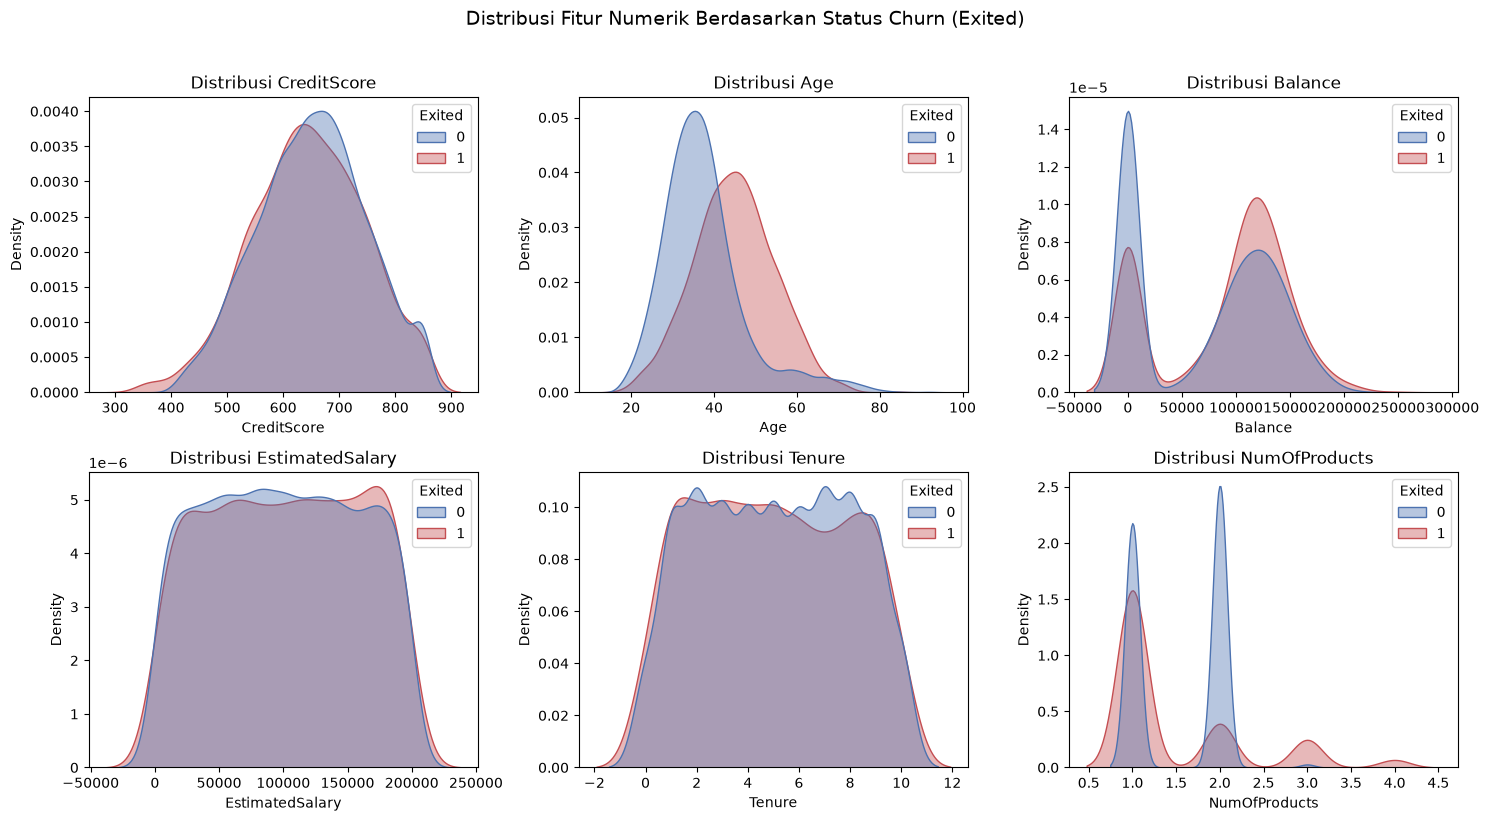

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
# Fitur numerik yang divisualisasikan
num_cols = ["CreditScore", "Age", "Balance", "EstimatedSalary", "Tenure", "NumOfProducts"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, col in zip(axes, num_cols):
    sns.kdeplot(
        data=df, x=col, hue="Exited", common_norm=False,
        fill=True, alpha=0.4, palette=["#4C72B0", "#C44E52"], ax=ax,
    )
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(col)

plt.suptitle("Distribusi Fitur Numerik Berdasarkan Status Churn (Exited)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

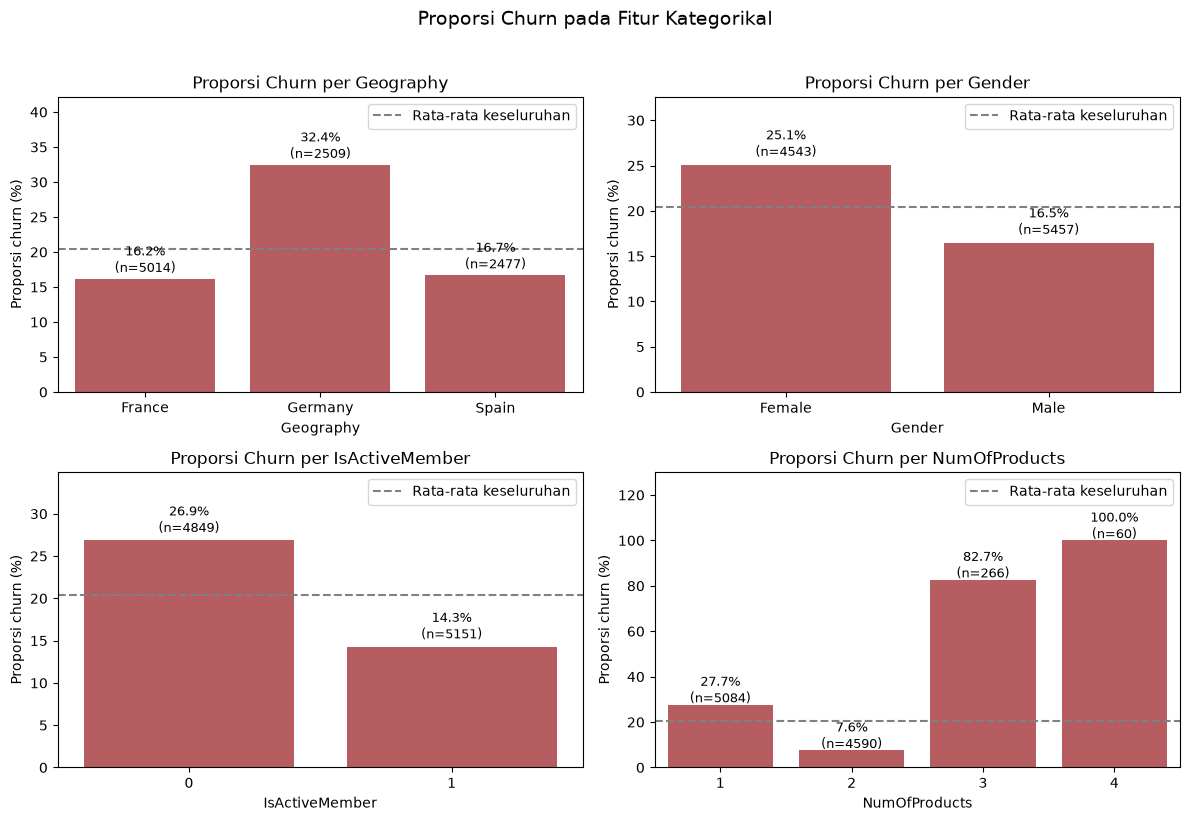


Geography
Geography
France     16.2%
Germany    32.4%
Spain      16.7%
Name: Exited, dtype: str

Gender
Gender
Female    25.1%
Male      16.5%
Name: Exited, dtype: str

IsActiveMember
IsActiveMember
0    26.9%
1    14.3%
Name: Exited, dtype: str

NumOfProducts
NumOfProducts
1     27.7%
2      7.6%
3     82.7%
4    100.0%
Name: Exited, dtype: str


In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
cat_cols = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, col in zip(axes, cat_cols):
    # Proporsi churn (rata-rata Exited) per kategori
    churn_rate = df.groupby(col)["Exited"].mean().sort_index() * 100
    n_per_cat = df[col].value_counts().sort_index()

    sns.barplot(x=churn_rate.index.astype(str), y=churn_rate.values,
                color="#C44E52", ax=ax)

    # Label persentase di atas bar, plus jumlah nasabah per kategori
    for i, (rate, n) in enumerate(zip(churn_rate.values, n_per_cat.values)):
        ax.text(i, rate + 1, f"{rate:.1f}%\n(n={n})", ha="center", fontsize=9)

    # Garis acuan: rata-rata churn keseluruhan
    ax.axhline(df["Exited"].mean() * 100, color="gray", linestyle="--", label="Rata-rata keseluruhan")
    ax.set_title(f"Proporsi Churn per {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Proporsi churn (%)")
    ax.set_ylim(0, churn_rate.max() * 1.3)
    ax.legend()

plt.suptitle("Proporsi Churn pada Fitur Kategorikal", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Versi tabel, berguna untuk dikutip di laporan
for col in cat_cols:
    print(f"\n{col}")
    print((df.groupby(col)["Exited"].mean() * 100).round(1).astype(str) + "%")

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [6]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.
cols_to_drop = ["RowNumber", "CustomerId", "Surname"]
df_clean = df.drop(columns=cols_to_drop)

print("Shape sebelum:", df.shape)
print("Shape sesudah:", df_clean.shape)
print("Kolom tersisa:", df_clean.columns.tolist())

Shape sebelum: (10000, 14)
Shape sesudah: (10000, 11)
Kolom tersisa: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [7]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

# Pisahkan fitur dan target
X = df_clean.drop(columns=["Exited"])
y = df_clean["Exited"]

# Langkah 1: pisahkan test set (15%) dari sisanya
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

# Langkah 2: pisahkan sisanya menjadi train (70% total) dan validation (15% total)
# 0.15 / 0.85 = 0.1765 dari X_temp setara 15% dari data awal
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=42
)

# Verifikasi ukuran dan proporsi kelas di tiap set
for name, ys in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11}: {len(ys):>5} sampel | churn = {ys.mean() * 100:.2f}%")

Train      :  7000 sampel | churn = 20.37%
Validation :  1500 sampel | churn = 20.33%
Test       :  1500 sampel | churn = 20.40%


In [8]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

# Kolom kategorikal: di-encode dengan one-hot
cat_features = ["Geography", "Gender"]

# Kolom numerik kontinu: di-scale dengan StandardScaler
num_features = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]

# Kolom biner (0/1): sudah dalam bentuk yang siap pakai, diteruskan apa adanya
bin_features = ["HasCrCard", "IsActiveMember"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_features),
        ("bin", "passthrough", bin_features),
    ]
)

# Fit HANYA pada train set, lalu transform ke ketiga set
X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

# Nama fitur hasil transformasi (berguna untuk interpretasi)
feature_names = preprocessor.get_feature_names_out()
print("Fitur setelah preprocessing:", list(feature_names))

print("Shape train:", X_train_p.shape)
print("Shape val  :", X_val_p.shape)
print("Shape test :", X_test_p.shape)

# Pastikan tipe data float32 untuk Keras, target dalam bentuk array
X_train_p = X_train_p.astype("float32")
X_val_p = X_val_p.astype("float32")
X_test_p = X_test_p.astype("float32")
y_train_arr, y_val_arr, y_test_arr = y_train.values, y_val.values, y_test.values

# Cek: rata-rata fitur numerik di train harus ~0 dan std ~1
print("\nMean fitur numerik (train):", X_train_p[:, :len(num_features)].mean(axis=0).round(3))
print("Std  fitur numerik (train):", X_train_p[:, :len(num_features)].std(axis=0).round(3))

Fitur setelah preprocessing: ['num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__EstimatedSalary', 'cat__Geography_Germany', 'cat__Geography_Spain', 'cat__Gender_Male', 'bin__HasCrCard', 'bin__IsActiveMember']
Shape train: (7000, 11)
Shape val  : (1500, 11)
Shape test : (1500, 11)

Mean fitur numerik (train): [ 0. -0.  0.  0. -0.  0.]
Std  fitur numerik (train): [1. 1. 1. 1. 1. 1.]


In [9]:
# Pastikan X dan y untuk train, validation, dan test berupa numpy array bertipe float32.
# Contoh: X_train = np.asarray(X_train, dtype="float32")

# Konversi semua X dan y ke numpy array float32
X_train = np.asarray(X_train_p, dtype="float32")
X_val   = np.asarray(X_val_p,   dtype="float32")
X_test  = np.asarray(X_test_p,  dtype="float32")

y_train = np.asarray(y_train_arr, dtype="float32")
y_val   = np.asarray(y_val_arr,   dtype="float32")
y_test  = np.asarray(y_test_arr,  dtype="float32")

# Verifikasi tipe dan bentuk
for name, arr in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test),
                  ("y_train", y_train), ("y_val", y_val), ("y_test", y_test)]:
    print(f"{name:<8}: shape={arr.shape}, dtype={arr.dtype}")

# Pastikan tidak ada NaN atau inf
print("\nAda NaN/inf:", any(not np.isfinite(a).all() for a in (X_train, X_val, X_test)))

X_train : shape=(7000, 11), dtype=float32
X_val   : shape=(1500, 11), dtype=float32
X_test  : shape=(1500, 11), dtype=float32
y_train : shape=(7000,), dtype=float32
y_val   : shape=(1500,), dtype=float32
y_test  : shape=(1500,), dtype=float32

Ada NaN/inf: False


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [10]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
# Baseline: Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

# Prediksi pada test set
y_pred_lr = log_reg.predict(X_test)               # label 0/1 (threshold 0.5)
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]   # probabilitas kelas 1 (churn)

# Ringkasan cepat
print("Accuracy :", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall   :", round(recall_score(y_test, y_pred_lr), 4))
print("F1-score :", round(f1_score(y_test, y_pred_lr), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_lr), 4))

Accuracy : 0.8027
Precision: 0.5424
Recall   : 0.2092
F1-score : 0.3019
ROC-AUC  : 0.7604


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer**. Karena ini klasifikasi biner, gunakan **1 neuron output dengan aktivasi Sigmoid** dan **Binary Cross-Entropy** sebagai loss function.

Contoh arsitektur: `Input → Dense(16, ReLU) → Dense(1, Sigmoid)`

In [11]:
# Definisikan arsitektur ANN sederhana menggunakan keras.Sequential.
# Gunakan keras.Input(shape=(jumlah_fitur,)) sebagai layer pertama, lalu layers.Dense untuk hidden layer dan output layer.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().

n_features = X_train.shape[1]   # 11 fitur setelah preprocessing

def build_ann_simple(n_features):
    model = keras.Sequential(
        [
            keras.Input(shape=(n_features,)),
            layers.Dense(16, activation="relu"),      # 1 hidden layer
            layers.Dense(1, activation="sigmoid"),    # output: probabilitas churn
        ],
        name="ann_simple",
    )
    return model

ann_simple = build_ann_simple(n_features)
ann_simple.summary()

Model: "ann_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209 (836.00 B)

 Trainable params: 209 (836.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compile model: tentukan optimizer (misalnya keras.optimizers.Adam(learning_rate=...)), loss="binary_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit(), gunakan validation_data=(X_val, y_val) agar loss dan accuracy validation tercatat setiap epoch.
# Simpan hasil model.fit() ke variabel history.
# Compile
ann_simple.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# Latih model; validation_data membuat val_loss dan val_accuracy tercatat tiap epoch
history_simple = ann_simple.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=1,
)

# Prediksi pada test set, disimpan untuk section evaluasi
y_prob_simple = ann_simple.predict(X_test).ravel()
y_pred_simple = (y_prob_simple >= 0.5).astype(int)

Epoch 1/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.6860 - loss: 0.6058 - val_accuracy: 0.7960 - val_loss: 0.4819
Epoch 2/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7991 - loss: 0.4527 - val_accuracy: 0.8027 - val_loss: 0.4302
Epoch 3/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8166 - loss: 0.4200 - val_accuracy: 0.8273 - val_loss: 0.4095
Epoch 4/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8277 - loss: 0.4024 - val_accuracy: 0.8400 - val_loss: 0.3944
Epoch 5/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8366 - loss: 0.3883 - val_accuracy: 0.8433 - val_loss: 0.3826
Epoch 6/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8429 - loss: 0.3776 - val_accuracy: 0.8493 - val_loss: 0.3732
Epoch 7/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8453 - loss: 0.3698 - val_accuracy: 0.8527 - val_loss: 0.3660
Epoch 8/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8470 - loss: 0.3641 - val_accu

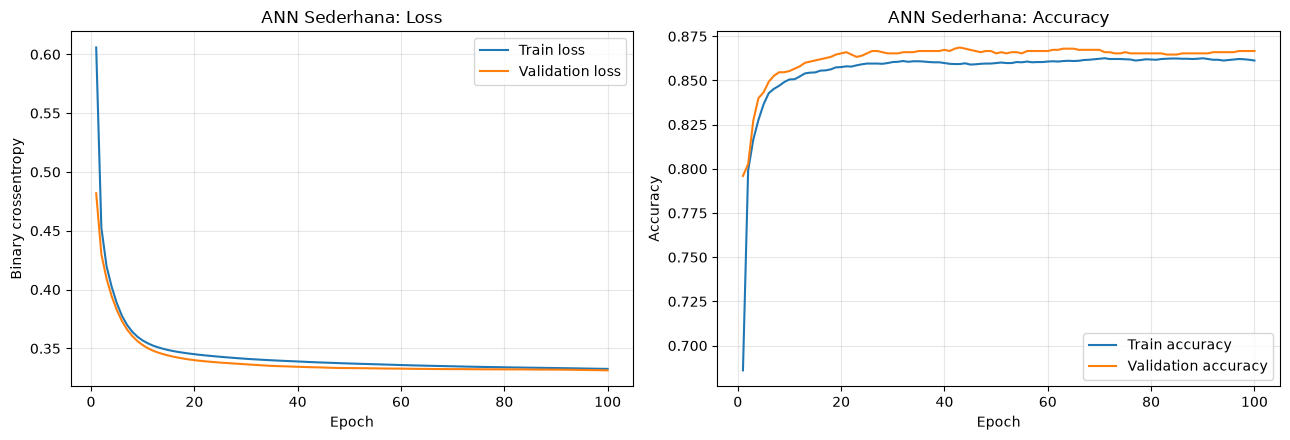

Val loss terendah: 0.3314 pada epoch 100 (dari 100 epoch)
Gap akhir (val_loss - train_loss): -0.0012


In [13]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot.
# Gunakan history.history["loss"], history.history["val_loss"], history.history["accuracy"], dan history.history["val_accuracy"].

def plot_learning_curve(history, title="Learning Curve"):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Loss
    axes[0].plot(epochs, h["loss"], label="Train loss")
    axes[0].plot(epochs, h["val_loss"], label="Validation loss")
    axes[0].set_title(f"{title}: Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Binary crossentropy")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Accuracy
    axes[1].plot(epochs, h["accuracy"], label="Train accuracy")
    axes[1].plot(epochs, h["val_accuracy"], label="Validation accuracy")
    axes[1].set_title(f"{title}: Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Epoch dengan val_loss terendah, berguna untuk analisis overfitting
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    print(f"Val loss terendah: {min(h['val_loss']):.4f} pada epoch {best_epoch} "
          f"(dari {len(h['loss'])} epoch)")
    print(f"Gap akhir (val_loss - train_loss): {h['val_loss'][-1] - h['loss'][-1]:.4f}")

plot_learning_curve(history_simple, title="ANN Sederhana")

In [14]:
# Lakukan prediksi pada test set dengan model.predict(X_test). Hasilnya berupa probabilitas kelas 1.
# Ubah menjadi label dengan threshold 0.5, lalu simpan probabilitas dan label untuk keperluan evaluasi.
# Prediksi probabilitas kelas 1 (churn) pada test set
y_prob_simple = ann_simple.predict(X_test, verbose=0).ravel()

# Ubah ke label dengan threshold 0.5
y_pred_simple = (y_prob_simple >= 0.5).astype(int)

# Pemeriksaan cepat
print("Shape probabilitas:", y_prob_simple.shape)
print("Contoh 5 probabilitas:", y_prob_simple[:5].round(3))
print("Contoh 5 label       :", y_pred_simple[:5])
print("Contoh 5 label asli  :", y_test[:5].astype(int))
print(f"\nProporsi prediksi churn: {y_pred_simple.mean() * 100:.1f}% "
      f"(proporsi churn sebenarnya di test: {y_test.mean() * 100:.1f}%)")

Shape probabilitas: (1500,)
Contoh 5 probabilitas: [0.04  0.695 0.135 0.145 0.103]
Contoh 5 label       : [0 1 0 0 0]
Contoh 5 label asli  : [0 1 0 1 0]

Proporsi prediksi churn: 12.9% (proporsi churn sebenarnya di test: 20.4%)


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [15]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan layers.Dropout(rate) di antara hidden layer.
# Tampilkan ringkasan model beserta jumlah parameternya.
def build_ann_deep(n_features, dropout_rate=0.3):
    model = keras.Sequential(
        [
            keras.Input(shape=(n_features,)),
            layers.Dense(64, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(32, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(16, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(1, activation="sigmoid"),
        ],
        name="ann_deep_dropout",
    )
    return model

ann_deep = build_ann_deep(n_features, dropout_rate=0.3)
ann_deep.summary()

Model: "ann_deep_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7800 - loss: 0.5064 - val_accuracy: 0.8000 - val_loss: 0.4287
Epoch 2/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8039 - loss: 0.4395 - val_accuracy: 0.8307 - val_loss: 0.4043
Epoch 3/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8134 - loss: 0.4176 - val_accuracy: 0.8453 - val_loss: 0.3833
Epoch 4/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8271 - loss: 0.3995 - val_accuracy: 0.8507 - val_loss: 0.3681
Epoch 5/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8333 - loss: 0.3932 - val_accuracy: 0.8527 - val_loss: 0.3620
Epoch 6/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8397 - loss: 0.3844 - val_accuracy: 0.8560 - val_loss: 0.3561
Epoch 7/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8446 - loss: 0.3767 - val_accuracy: 0.8593 - val_loss: 0.3552
Epoch 8/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8413 - loss: 0.3775 - val_accu

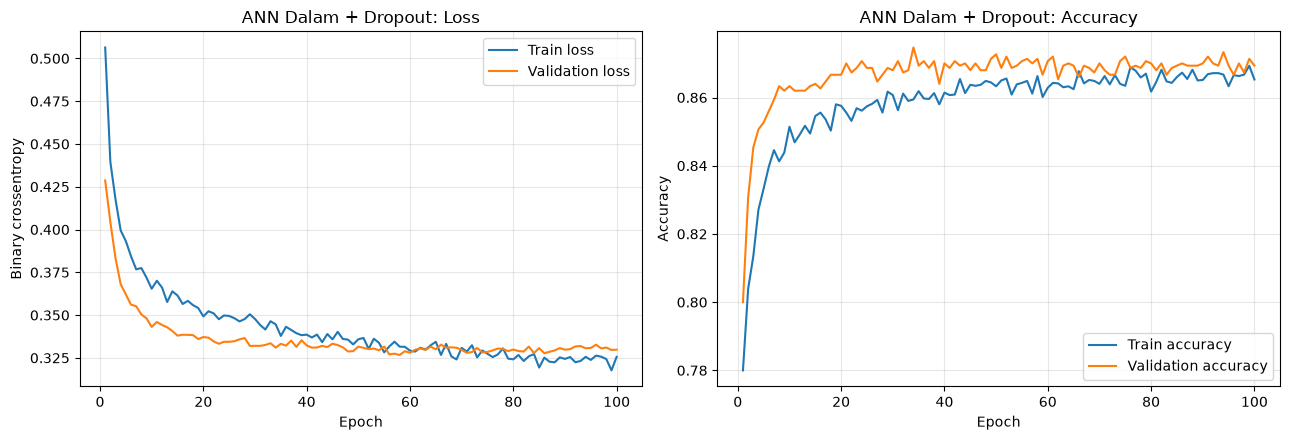

Val loss terendah: 0.3267 pada epoch 58 (dari 100 epoch)
Gap akhir (val_loss - train_loss): 0.0042


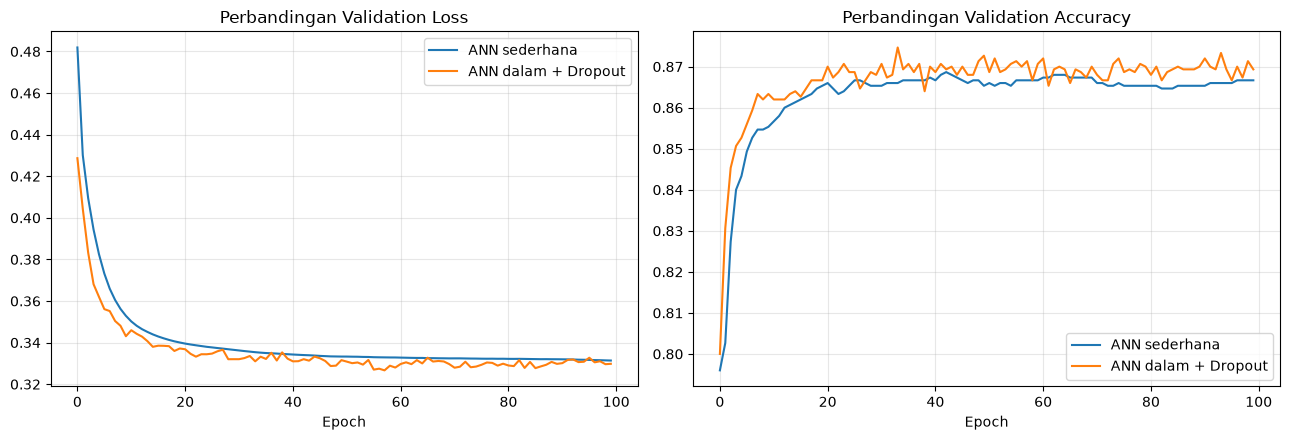

In [16]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?
# Compile: konfigurasi sama dengan ANN sederhana supaya perbandingan adil
ann_deep.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

history_deep = ann_deep.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=1,
)

# Learning curve model ini
plot_learning_curve(history_deep, title="ANN Dalam + Dropout")

# Prediksi test set, disimpan untuk section evaluasi
y_prob_deep = ann_deep.predict(X_test, verbose=0).ravel()
y_pred_deep = (y_prob_deep >= 0.5).astype(int)

# Perbandingan langsung dengan ANN sederhana (kurva val_loss dan val_accuracy)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for hist, label in [(history_simple, "ANN sederhana"), (history_deep, "ANN dalam + Dropout")]:
    axes[0].plot(hist.history["val_loss"], label=label)
    axes[1].plot(hist.history["val_accuracy"], label=label)
axes[0].set_title("Perbandingan Validation Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_title("Perbandingan Validation Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
# Prediksi probabilitas kelas 1 (churn) pada test set
y_prob_deep = ann_deep.predict(X_test, verbose=0).ravel()

# Label dengan threshold 0.5
y_pred_deep = (y_prob_deep >= 0.5).astype(int)

# Pemeriksaan cepat
print("Shape probabilitas:", y_prob_deep.shape)
print("Contoh 5 probabilitas:", y_prob_deep[:5].round(3))
print("Contoh 5 label       :", y_pred_deep[:5])
print("Contoh 5 label asli  :", y_test[:5].astype(int))
print(f"\nProporsi prediksi churn: {y_pred_deep.mean() * 100:.1f}% "
      f"(proporsi churn sebenarnya di test: {y_test.mean() * 100:.1f}%)")

Shape probabilitas: (1500,)
Contoh 5 probabilitas: [0.114 0.472 0.158 0.164 0.116]
Contoh 5 label       : [0 0 0 0 0]
Contoh 5 label asli  : [0 1 0 1 0]

Proporsi prediksi churn: 11.7% (proporsi churn sebenarnya di test: 20.4%)


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

Class weight: {0: 0.6279153211338356, 1: 2.4544179523141656}
Val loss terendah | sederhana: 0.3314 | dalam+Dropout: 0.3267
Arsitektur terpilih: ANN dalam + Dropout
Epoch 1/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6021 - loss: 0.6342 - val_accuracy: 0.7433 - val_loss: 0.5619
Epoch 2/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7054 - loss: 0.5832 - val_accuracy: 0.7600 - val_loss: 0.5023
Epoch 3/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7264 - loss: 0.5551 - val_accuracy: 0.7673 - val_loss: 0.4847
Epoch 4/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7446 - loss: 0.5317 - val_accuracy: 0.7953 - val_loss: 0.4611
Epoch 5/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7483 - loss: 0.5205 - val_accuracy: 0.7933 - val_loss: 0.4635
Epoch 6/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7534 - loss: 0.5133 - val_accuracy: 0.7960 - val_loss: 0.4457
Epoch 7/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accurac

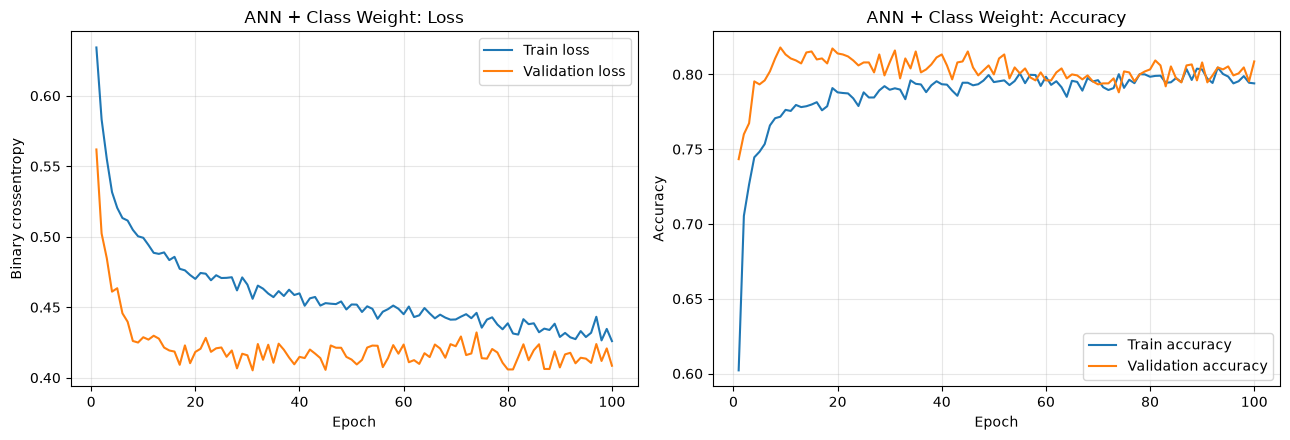

Val loss terendah: 0.4052 pada epoch 31 (dari 100 epoch)
Gap akhir (val_loss - train_loss): -0.0175

Recall churn   : 0.732
Precision churn: 0.4807
F1 churn       : 0.5803
Proporsi prediksi churn: 31.1%


In [18]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung bobot setiap kelas berdasarkan train set, misalnya dengan sklearn.utils.class_weight.compute_class_weight("balanced", ...).
# Masukkan ke model.fit() melalui parameter class_weight={0: bobot_kelas_0, 1: bobot_kelas_1}.
# 1) Hitung class weight dari TRAIN set saja
classes = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weight:", class_weight)   # kira-kira {0: 0.63, 1: 2.45}

# 2) Pilih arsitektur terbaik berdasarkan val_loss terendah dari kedua ANN sebelumnya
best_val_simple = min(history_simple.history["val_loss"])
best_val_deep = min(history_deep.history["val_loss"])
print(f"Val loss terendah | sederhana: {best_val_simple:.4f} | dalam+Dropout: {best_val_deep:.4f}")

use_deep = best_val_deep <= best_val_simple
print("Arsitektur terpilih:", "ANN dalam + Dropout" if use_deep else "ANN sederhana")

# 3) Buat ulang model (bobot mulai dari awal)
tf.keras.utils.set_random_seed(42)
if use_deep:
    ann_cw = build_ann_deep(n_features, dropout_rate=0.3)
else:
    ann_cw = build_ann_simple(n_features)

ann_cw.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# 4) Latih dengan class_weight, konfigurasi lain identik
history_cw = ann_cw.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    class_weight=class_weight,
    verbose=1,
)

# 5) Learning curve dan prediksi test set
plot_learning_curve(history_cw, title="ANN + Class Weight")

y_prob_cw = ann_cw.predict(X_test, verbose=0).ravel()
y_pred_cw = (y_prob_cw >= 0.5).astype(int)

print("\nRecall churn   :", round(recall_score(y_test, y_pred_cw), 4))
print("Precision churn:", round(precision_score(y_test, y_pred_cw), 4))
print("F1 churn       :", round(f1_score(y_test, y_pred_cw), 4))
print(f"Proporsi prediksi churn: {y_pred_cw.mean() * 100:.1f}%")

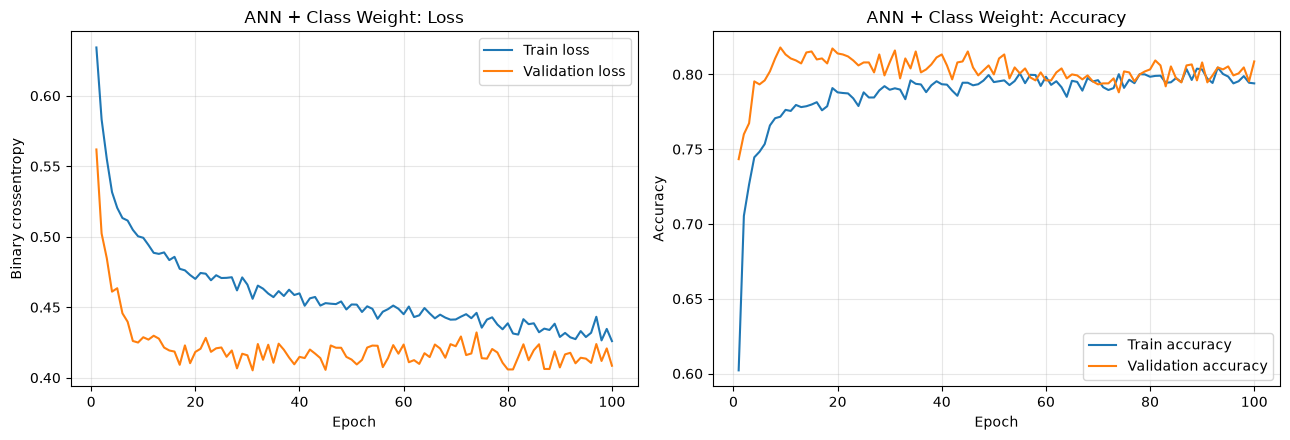

Val loss terendah: 0.4052 pada epoch 31 (dari 100 epoch)
Gap akhir (val_loss - train_loss): -0.0175
Contoh 5 probabilitas: [0.115 0.859 0.339 0.49  0.225]
Contoh 5 label       : [0 1 0 0 0]
Contoh 5 label asli  : [0 1 0 1 0]

Proporsi prediksi churn: 31.1% (proporsi churn sebenarnya di test: 20.4%)


In [19]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
# Learning curve model class weight
plot_learning_curve(history_cw, title="ANN + Class Weight")

# Prediksi test set: probabilitas kelas 1 dan label (threshold 0.5)
y_prob_cw = ann_cw.predict(X_test, verbose=0).ravel()
y_pred_cw = (y_prob_cw >= 0.5).astype(int)

# Pemeriksaan cepat
print("Contoh 5 probabilitas:", y_prob_cw[:5].round(3))
print("Contoh 5 label       :", y_pred_cw[:5])
print("Contoh 5 label asli  :", y_test[:5].astype(int))
print(f"\nProporsi prediksi churn: {y_pred_cw.mean() * 100:.1f}% "
      f"(proporsi churn sebenarnya di test: {y_test.mean() * 100:.1f}%)")

# 4. Evaluasi Model

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8027,0.5424,0.2092,0.3019,0.7604
ANN Sederhana,0.8540,0.7254,0.4575,0.5611,0.8491
ANN Dalam + Dropout,0.8567,0.7600,0.4346,0.5530,0.8538
ANN + Class Weight,0.7840,0.4807,0.7320,0.5803,0.8524


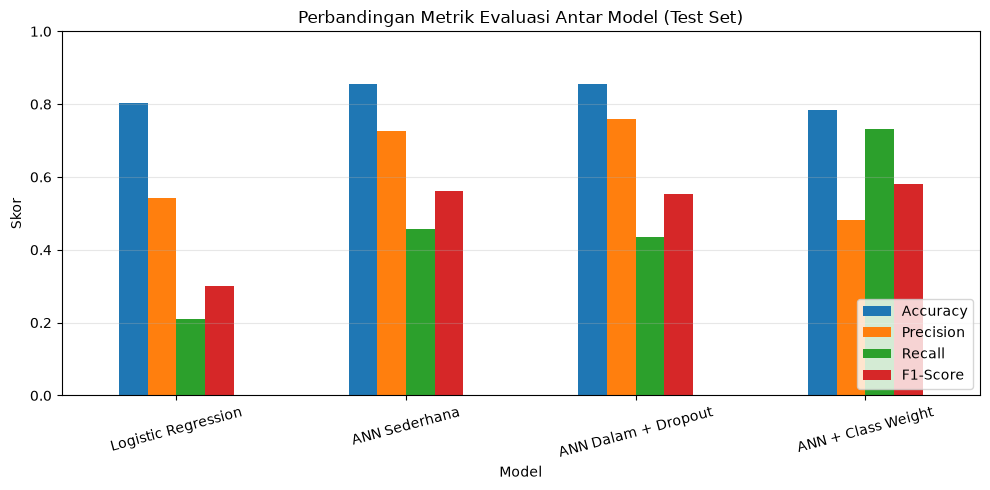

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
# Kumpulkan prediksi semua model (semua dievaluasi pada test set, threshold 0.5)
results = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "ANN Sederhana":       (y_pred_simple, y_prob_simple),
    "ANN Dalam + Dropout": (y_pred_deep, y_prob_deep),
    "ANN + Class Weight":  (y_pred_cw, y_prob_cw),
}

rows = []
for name, (y_pred, y_prob) in results.items():
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall":    recall_score(y_test, y_pred),
        "F1-Score":  f1_score(y_test, y_pred),
        "ROC-AUC":   roc_auc_score(y_test, y_prob),   # kolom tambahan, bebas threshold
    })

df_results = pd.DataFrame(rows).set_index("Model").round(4)

# Tabel dengan nilai terbaik per kolom disorot
display(df_results.style.highlight_max(axis=0, color="#cfe8cf").format("{:.4f}"))

# Versi bar chart untuk memudahkan perbandingan visual
df_results.drop(columns="ROC-AUC").plot(kind="bar", figsize=(10, 5), rot=15, ylim=(0, 1))
plt.title("Perbandingan Metrik Evaluasi Antar Model (Test Set)")
plt.ylabel("Skor")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

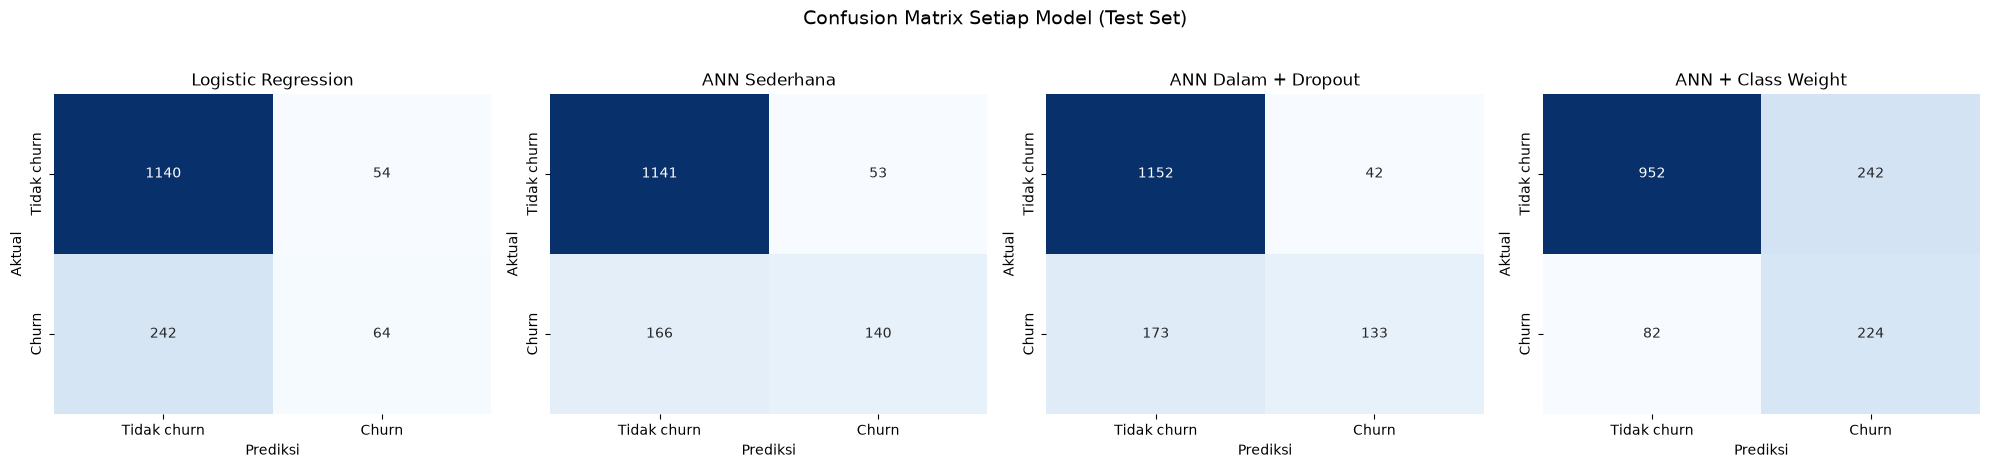

Logistic Regression    | TP= 64 FN=242 FP= 54 TN=1140
ANN Sederhana          | TP=140 FN=166 FP= 53 TN=1141
ANN Dalam + Dropout    | TP=133 FN=173 FP= 42 TN=1152
ANN + Class Weight     | TP=224 FN= 82 FP=242 TN= 952


In [21]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for ax, (name, (y_pred, _)) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Tidak churn", "Churn"],
        yticklabels=["Tidak churn", "Churn"],
    )
    ax.set_title(name)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.suptitle("Confusion Matrix Setiap Model (Test Set)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

# Ringkasan angka FN dan FP per model, untuk dikutip di laporan
for name, (y_pred, _) in results.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f"{name:<22} | TP={tp:>3} FN={fn:>3} FP={fp:>3} TN={tn:>4}")

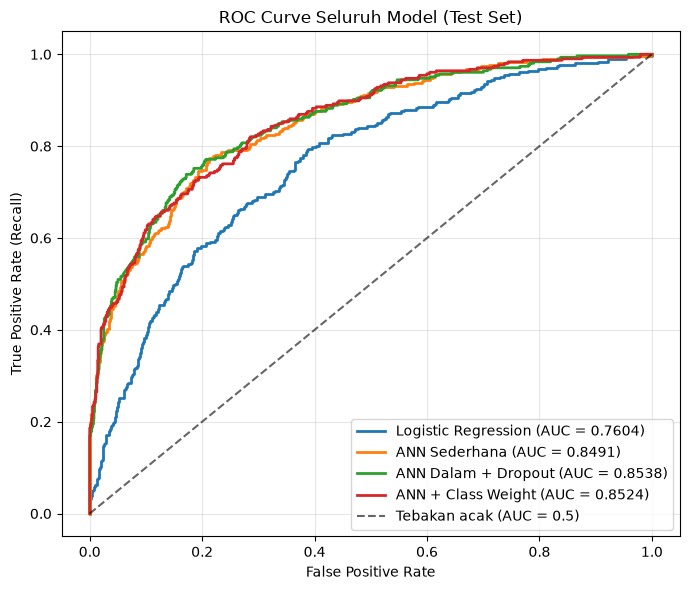

In [22]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))

for name, (_, y_prob) in results.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.4f})")

# Garis acuan: tebakan acak (AUC = 0.5)
plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Tebakan acak (AUC = 0.5)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Seluruh Model (Test Set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Analisis

1. Ketiga ANN jauh mengungguli Logistic Regression. Selisih AUC sekitar 0,09-0,09+ (0,76 vs 0,85) cukup besar. Kurva biru berada di bawah ketiga kurva ANN hampir di seluruh rentang FPR. Contohnya, pada FPR 0,2 recall Logistic Regression sekitar 0,57, sedangkan ANN sekitar 0,75. Ini mendukung argumen bahwa hubungan fitur dan churn bersifat non-linear, terutama NumOfProducts (churn sekitar 8% pada 2 produk, tetapi 83-100% pada 3-4 produk) dan interaksi seperti Age dengan IsActiveMember. Model linear tidak bisa menangkap pola itu.

2. Ketiga ANN nyaris berhimpitan. Selisih AUC antar-ANN hanya 0,0047 (0,8491 sampai 0,8538), dan kurvanya saling bersilangan. Dengan satu kali training, satu seed, dan sekitar 306 sampel churn di test set, selisih sekecil itu masih dalam rentang variasi acak. Jangan menyimpulkan bahwa ANN Dalam + Dropout “lebih baik” hanya karena AUC-nya tertinggi. Kesimpulan yang jujur: ketiga ANN setara dalam kemampuan memisahkan kelas.

3. Class weight tidak menaikkan AUC. AUC model class weight (0,8524) praktis sama dengan model ANN lain. Ini sesuai teori: class weight menggeser distribusi probabilitas, bukan meningkatkan kemampuan membedakan churn dan non-churn. Perbedaan recall yang besar di tabel metrik berasal dari pergeseran titik operasi pada kurva, bukan dari model yang “lebih pintar”.

4. Ada batas informasi pada data. Dari kedalaman 1 layer (209 parameter) ke 3 layer (3.393 parameter), AUC hanya naik sekitar 0,005. Menambah kapasitas model memberi hasil yang hampir nol, tanda bahwa batasnya ada di informasi fitur, bukan di arsitektur.

5. Bentuk kurva. Semua ANN naik tajam di FPR rendah (recall sekitar 0,5-0,6 pada FPR 0,1) lalu melandai. Artinya sebagian churn mudah dikenali (misalnya usia 40-50 dengan 3-4 produk atau di Germany), tetapi sisanya sulit dipisahkan tanpa mengorbankan banyak false positive.

# 6. Kesimpulan dan Saran

1. Penyesuaian threshold. Cari threshold yang memaksimalkan F1 pada validation set, lalu terapkan ke test set. ANN biasa dengan threshold yang disesuaikan kemungkinan menyamai ANN class weight, dan ini cara yang lebih terkontrol untuk mengatur trade-off precision-recall.
2. Precision-Recall curve. ROC bisa tampak terlalu optimistis pada data imbalanced. PR curve lebih sensitif terhadap performa kelas minoritas.
3. Ulangi training dengan beberapa seed (misalnya 5) dan laporkan rata-rata ± simpangan baku. Dengan begitu kamu bisa memastikan apakah selisih antarmodel nyata atau hanya noise.
4. Gunakan EarlyStopping (monitor="val_loss", restore_best_weights=True) agar training berhenti saat val loss tidak lagi membaik, bukan dibiarkan 100 epoch.
5. Feature engineering. Coba fitur seperti Balance == 0, rasio Balance / EstimatedSalary, atau interaksi Age × IsActiveMember. Karena menambah layer hampir tidak membantu, fitur baru lebih menjanjikan.
6. Pembanding non-neural. Coba Random Forest atau Gradient Boosting. Pada data tabular seperti ini, model berbasis pohon sering menyamai atau mengungguli ANN dengan tuning yang lebih sedikit.
7. Teknik imbalance lain, seperti SMOTE atau oversampling, sebagai alternatif class weight. Terapkan hanya pada train set.
Cross-validation (stratified k-fold) untuk estimasi performa yang lebih stabil daripada satu kali split.